### Homework 5: Gaussian Elimination


In [25]:
import numpy as np
import time
import matplotlib.pyplot as plt

##### Problem 1: 
Implement Algorithm 17.1: back substitution and forward substitution (analogue for lower triang matrices). Algorithm 20.1: Gaussian Eliminationian Eliminationian Elimination. Algorithm 21.1: Partial Pivoting. Algorithm in 21.3: Pivoting Columns as shown with permutation matrix Q in 21.3. Gaussian Eliminationian Eliminationian Eliminationian Eliminationian Elimination with complete pivoting --> should survive any square matrix elim.

In [20]:
def gaussian_elim(A):
    m = len(A)
    U = A.astype(float)
    L= np.eye(m)
    for k in range(m-1):
        L[k+1:, k] = U[k+1:, k]/ U[k,k]
        U[k+1:, k:] -= np.outer(L[k+1:, k], U[k,k:])
    return L, U

# Verify correctness:
A = np.array([[1,1,1], [1,1,1], [0,0,1]])
print(gaussian_elim(A))

def gaussian_complete_pivot(A):
    m = len(A)
    U = A.astype(float)
    L = np.eye(m)
    p = np.arange(m)
    q = np.arange(m)
    for k in range(m-1):
        i, j = np.unravel_index(np.argmax(abs(U[k:, k:])), (m-k, m-k))
        i += k; j += k
        U[[k, i], k:] = U[[i, k], k:]
        L[[k, i], :k] = L[[i, k], :k]
        p[[k, i]] = p[[i, k]]
        U[:, [k, j]] = U[:, [j, k]]
        q[[k, j]] = q[[j, k]]
        L[k+1:, k] = U[k+1:, k] / U[k, k]
        U[k+1:, k:] -= np.outer(L[k+1:, k], U[k, k:])
    return L, U, p, q

A = np.array([[1,1,1], [1,1,1], [0,0,1]])
print(gaussian_complete_pivot(A))

def back_substitution(R, b):
    m = len(b)
    x = np.zeros(m)
    for j in range(m-1, -1, -1):
        x[j] = (b[j] - R[j, j+1:] @ x[j+1:]) / R[j, j]
    return x

# Verify correctness:
# A = np.array([[1,1,1], [0,1,2], [0,0,2]])
# print(back_substitution(A, [1/2,2,1]))

def forward_substitution(L, b):
    m = len(b)
    y = np.zeros(m)
    for j in range(m):
        y[j] = (b[j] - L[j, :j] @ y[:j]) / L[j, j]
    return y

# Verify correctness:
# A = np.array([[0,0,2], [0,1,2], [1,1,1]])
# print(forward_substitution(A, [1,2,1/2]))

def gaussian_partial_pivot(A):
    m = len(A)
    U = A.astype(float)
    L = np.eye(m); p = np.arange(m)
    for k in range(m-1):
        i = k + np.argmax(abs(U[k:, k]))
        U[[k, i], k:] = U[[i, k], k:]
        L[[k, i], :k] = L[[i, k], :k]
        p[[k, i]] = p[[i, k]]
        L[k+1:, k] = U[k+1:, k] / U[k, k]
        U[k+1:, k:] -= np.outer(L[k+1:, k], U[k, k:])
    return L, U, p

# Verify correctness:
# A = np.array([[1,1,1], [1,1,1], [0,0,1]])
# gaussian_partial_pivot(A)

def gaussian_column_pivot(A):
    m = len(A)
    U = A.astype(float)
    L = np.eye(m)
    q = np.arange(m)
    for k in range(m-1):
        j = k + np.argmax(abs(U[k, k:]))
        U[:, [k, j]] = U[:, [j, k]]
        q[[k, j]] = q[[j, k]]
        L[k+1:, k] = U[k+1:, k] / U[k, k]
        U[k+1:, k:] -= np.outer(L[k+1:, k], U[k, k:])
    return L, U, q

# Verify correctness:
# A = np.array([[1,1,1], [1,1,1], [0,0,1]])
# print(gaussian_column_pivot(A))



(array([[ 1.,  0.,  0.],
       [ 1.,  1.,  0.],
       [ 0., nan,  1.]]), array([[ 1.,  1.,  1.],
       [ 0.,  0.,  0.],
       [ 0., nan, nan]]))
(array([[1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 1.]]), array([[1., 1., 1.],
       [0., 1., 0.],
       [0., 0., 0.]]), array([0, 2, 1]), array([0, 2, 1]))


/var/folders/qx/6q0bbwqn6mn5z_p8fwf6210h0000gn/T/ipykernel_88915/4263528915.py:6: RuntimeWarning: invalid value encountered in divide
  L[k+1:, k] = U[k+1:, k]/ U[k,k]


##### Problem 2:
 Gen $A_0$ as a random permut. matrix, and define $A = A_0 + n^{-1}M$ where M is $n \times n$ whose entries are $\mathcal{N}(0,1)$. Set $\vec{x}= [1,2,3,\dots, n]^T$ and $\vec{b} := A\vec x$.

In [ ]:
# np.random.randn(3,3)
# A = np.eye(3)
# print(A)
# per = A[[1,0,2]]
# print(per)
# # np.random.permutation(3)

In [18]:
def make_A(n):
    A0 = np.eye(n)[np.random.permutation(n)]
    add = np.random.randn(n,n)/n
    A = A0 + add
    x = np.arange(1, n+1, dtype=int)
    return A, x, A @ x

##### Problem 3:

Apply Algorithms in 1 to the above generated values, and solve $A \vec x = \vec b$ for $n = 2^8, 2^9, 2^{10}, 2^{11}$ and compute:

1) Runtime on Computer
2) The error $\frac{|| \mathbf{\tilde x} - \mathbf{x}||}{\| \mathbf{x}\|}$ using 2-norm
3) Error $\frac{\| \tilde P A \tilde Q - \tilde L \tilde U\|}{\| A \|}$ using induced 2 norm


In [ ]:
N = [2**8, 2**9, 2**10, 2**11]
M = ['Gaussian Elimination', 'Partial Pivoting', 'Column Pivoting', 'Complete Pivoting']

vector_error = {m: [] for m in M}
matrix_error = {m: [] for m in M}
times = {m: [] for m in M}

def select_method(method, A, b):
    m = len(b)
    I = np.arange(m)
    if method == 'Gaussian Elimination':
        L, U = gaussian_elim(A)
        p = q = I
    elif method == 'Partial Pivoting':
        L, U, p = gaussian_partial_pivot(A)
        q = I
    elif method == 'Column Pivoting':
        L, U, q = gaussian_column_pivot(A)
        p = I
    else:
        L, U, p, q = gaussian_complete_pivot(A)
    y = back_substitution(U, forward_substitution(L, b[p]))
    x = np.zeros(m)
    x[q] = y
    return x, A[p][:, q] - L @ U

for n in N:
    print('='*50)
    A, x, b = make_A(n)
    print(f"size (n): {n}")
    for m in M:
        t = time.perf_counter()
        xt, E = select_method(m, A, b)
        t = time.perf_counter() - t
        error1=  np.linalg.norm(xt - x) / np.linalg.norm(x)
        matrix_err = np.linalg.norm(E, 2) / np.linalg.norm(A, 2)
        times[m].append(t)
        vector_error[m].append(error1)
        matrix_error[m].append(matrix_err)
        print('-'*50)
        print(f"method: {m}\nruntime: {t}")
        print(f"vector error: {error1}\nmatrix error: {matrix_err}")
        print('-'*50)
    print('='*50)

size (n): 256
--------------------------------------------------
method: Gaussian Elimination
runtime: 0.023316584061831236
vector error: 6.594698224548364e-12
matrix error: 4.849404528817124e-11
--------------------------------------------------
--------------------------------------------------
method: Partial Pivoting
runtime: 0.010276749962940812
vector error: 7.543751531013496e-16
matrix error: 2.0468870367698333e-15
--------------------------------------------------
--------------------------------------------------
method: Column Pivoting
runtime: 0.012342708883807063
vector error: 5.850719964954853e-16
matrix error: 1.8408047912122124e-15
--------------------------------------------------
--------------------------------------------------
method: Complete Pivoting
runtime: 0.02079754206351936
vector error: 5.773918156514249e-16
matrix error: 1.8398971293784962e-15
--------------------------------------------------
size (n): 512
--------------------------------------------------

Note: The following plots were visualized using the aid of AI. Data was accumulated into dictionaries in the above cells, and Claude Code was prompted to plot them on a transformed $\log_{10}$ scale on the y-axis so that inter-method plots are more comparable.

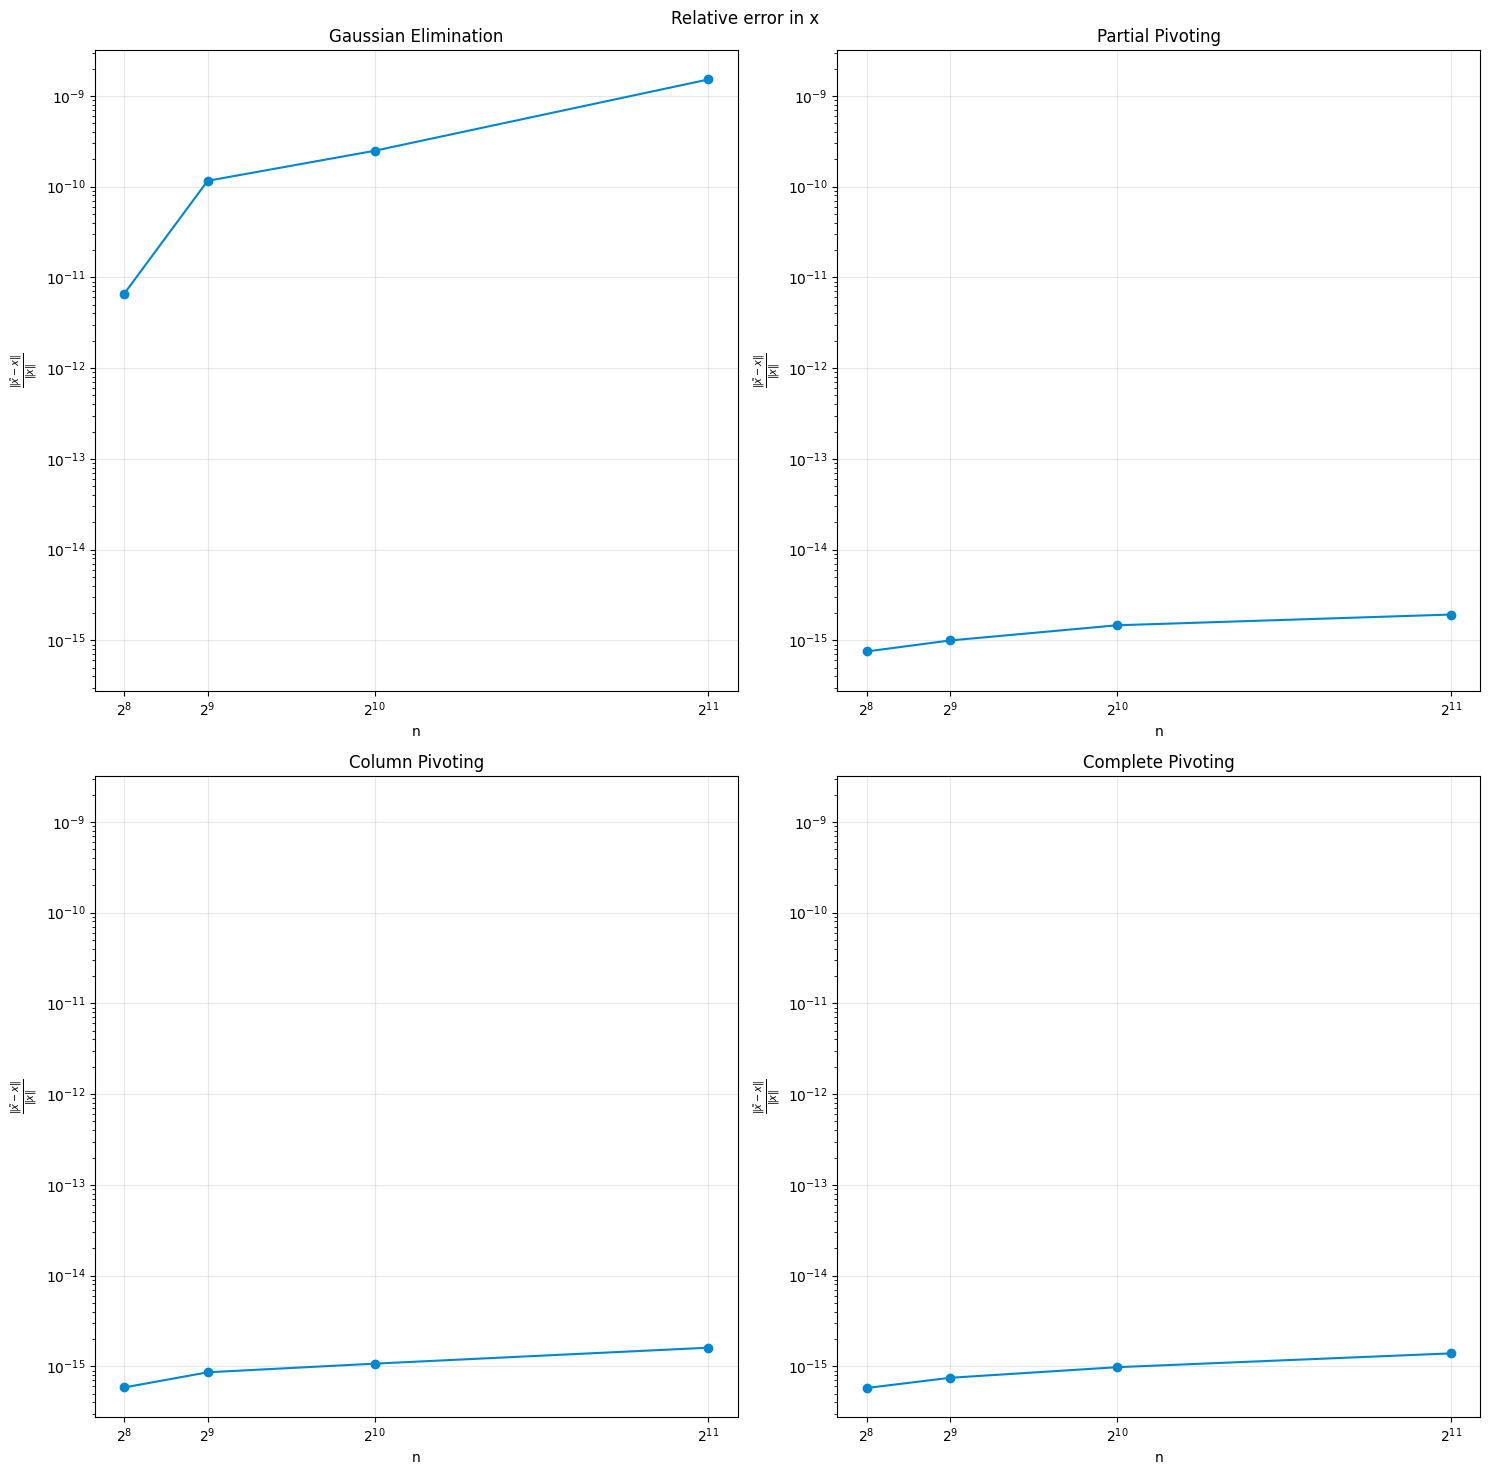

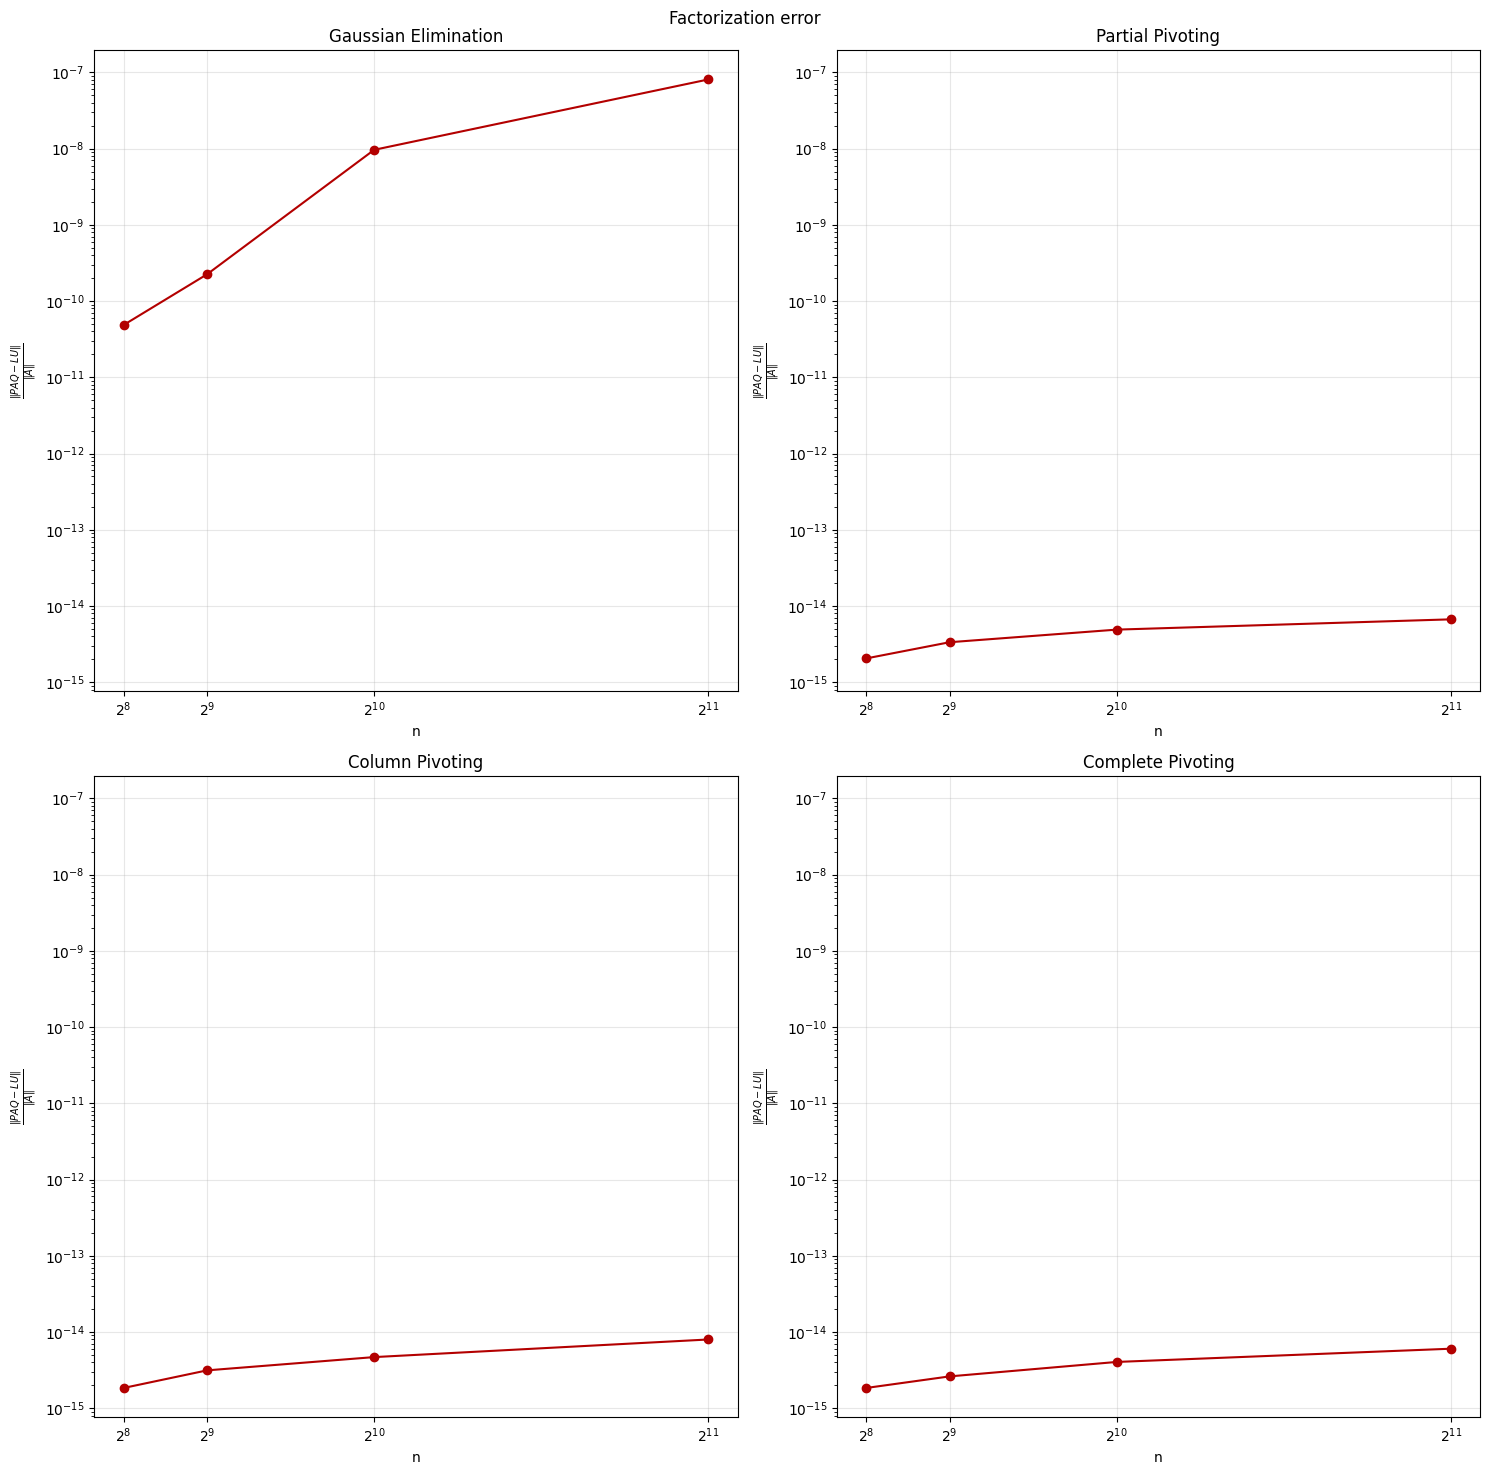

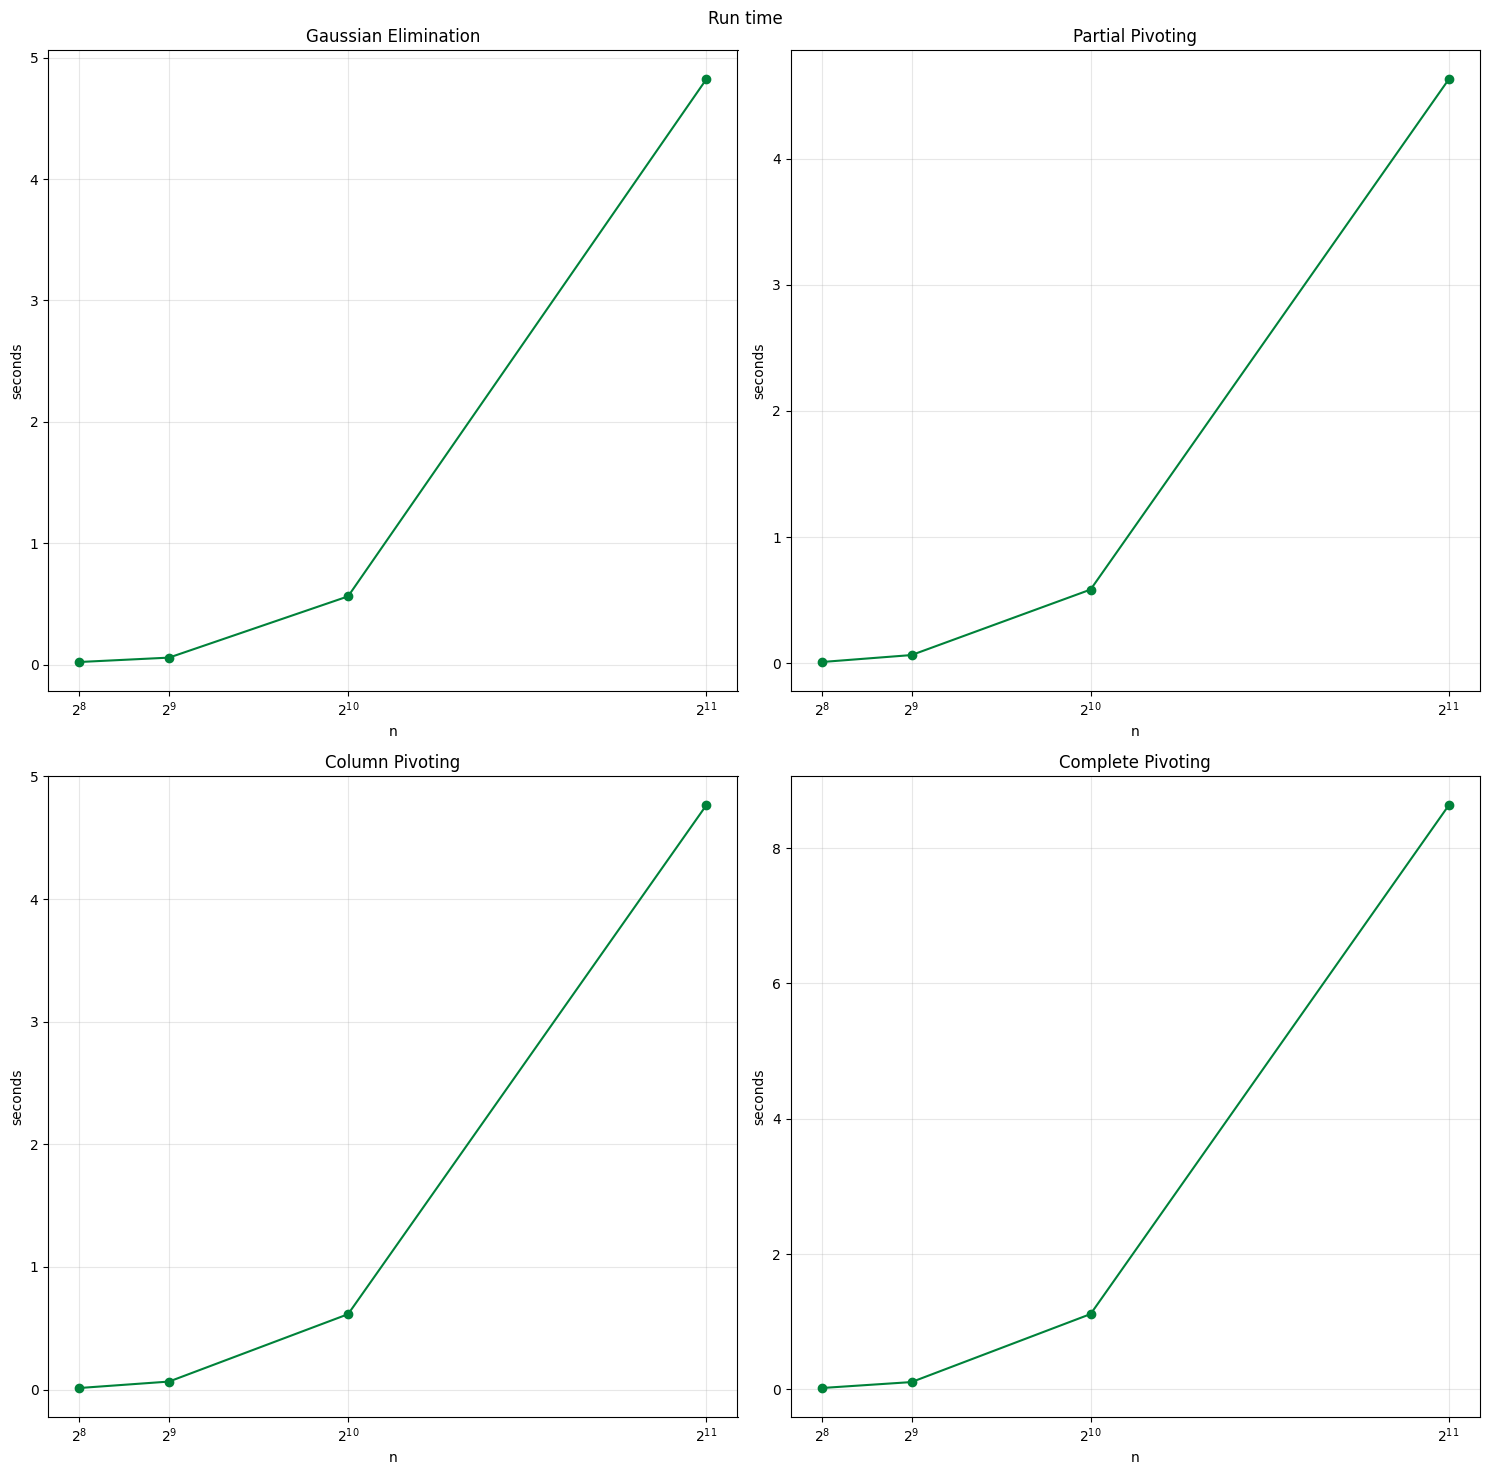

In [37]:
def plot_results(data, title, ylabel, color, log=False):
    fig, axes = plt.subplots(2, 2, figsize=(15, 15), sharex=True, sharey=log)
    for ax, m in zip(axes.flat, M):
        ax.plot(N, data[m], 'o-', color=color)
        if log:
            ax.set_yscale('log')
        ax.set_xticks(N)
        ax.set_xticklabels([f'$2^{{{int(np.log2(n))}}}$' for n in N])
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.set_title(m)
        ax.set_xlabel('n')
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_results(vector_error, 'Relative error in x', r'$\frac{\|\tilde{x}-x\|}{\|x\|}$', '#0087D1', log=True)
plot_results(matrix_error, 'Factorization error', r'$\frac{\|PAQ-LU\|}{\|A\|}$', '#B30000', log=True)
plot_results(times, 'Run time', 'seconds', '#00823A')

#### Problem 4: Discussion of Findings

**Answer:**

Note first that the runtime of complete pivoting is noticably larger for large n values, relative to other methods we are taking into consideration. The question remains: is complete pivoting worth it for its relatively high computational cost?

Given our matrix $A$ is a permutation matrix (well conditioned: orthogonal with $\kappa(A) = 1$) with some added gaussian noise, which approaches zero as n increases, our matrix setting is asymptotically well conditioned. So, any error produced is purely a result of the algorithm itself.

See here, for our case analysis of $A$, all three methods; partial row, column and complete pivoting are all backward stable, given the relative error between solved $\tilde x$ and the assumed true $x$ are close to floating point precision. Comparatively, no pivoting gives an unstable result whose relative error gets worse as n grows, moving significantly above machine precision. The factorization relative error showcases similar patterns across algorithms, with no pivot Gaussian elimination producing relatively larger relative errors that grow with n.

This is because no pivoting defaults to pivoting around diagonal entries that are mostly noise scaled by a factor of $\frac{1}{n}$, which produces large multipliers, and completely ignores the true pivots, which ideally should have been the entires = 1 in our permulation matrix. Each elimination step then subtracts a large quantity, (the large multiplier times an entry of the pivot row), from an entry of the remaining submatrix that is of order 1 or 1/n. Every floating-point operation has a rounding error proportional to the magnitude of the numbers involved, which scale with n, which is exactly the increasing error we see in the graphs.

This explicitly illustrates the precision advantage of complete pivoting over no pivoting Gaussian Elimination, however, in our case doesnot necessarily validate choosing complete pivoting for solving a system of linear equations expressed in our well conditioned matrix. This is because we can simply deploy partial pivoting for a well conditioned matrix like $A$ and still obtain a stable algorithm that solves the system of equations, and produces errors bounded to floating point precision in comparatively less time. Therefore, for our case, the time-precision tradeoff for complete pivoting is not worth it.